# Assignment 1 – Data Exploration
## Global Power Plant Database

This notebook explores the Global Power Plant Database (WRI v1.3.0)
for the JBI100 Visualization project.

The purpose is to understand the dataset's structure, attributes,
distributions, and data quality before designing the visualization.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## Loading the dataset

The dataset is provided as a CSV file. Each row represents
a power plant, and each column represents an attribute.

In [4]:
data_path = Path("data/raw/global_power_plant_database.csv")

if not data_path.exists():
    data_path = Path("../data/raw/global_power_plant_database.csv")

df = pd.read_csv(data_path, low_memory=False)

print("Dataset successfully loaded.")

Dataset successfully loaded.


In [5]:
# Display the first five rows
display(df.head())

,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017
0,AFG,Afghanistan,Kajaki Hydroelectric Power Plant Afghanistan,GEODB0040538,33.0,32.322,65.1190,Hydro,NaN,NaN,...,123.77,162.90,97.39,137.76,119.50,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
1,AFG,Afghanistan,Kandahar DOG,WKS0070144,10.0,31.670,65.7950,Solar,NaN,NaN,...,18.43,17.48,18.25,17.70,18.29,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
2,AFG,Afghanistan,Kandahar JOL,WKS0071196,10.0,31.623,65.7920,Solar,NaN,NaN,...,18.64,17.58,19.10,17.62,18.72,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
3,AFG,Afghanistan,Mahipar Hydroelectric Power Plant Afghanistan,GEODB0040541,66.0,34.556,69.4787,Hydro,NaN,NaN,...,225.06,203.55,146.90,230.18,174.91,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
4,AFG,Afghanistan,Naghlu Dam Hydroelectric Power Plant Afghanistan,GEODB0040534,100.0,34.641,69.7170,Hydro,NaN,NaN,...,406.16,357.22,270.99,395.38,350.80,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1


In [6]:
# Display the last five rows
display(df.tail())

,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017
34931,ZMB,Zambia,Ndola,WRI1022386,50.0,-12.9667,28.6333,Oil,NaN,NaN,...,NaN,NaN,NaN,NaN,183.79,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1
34932,ZMB,Zambia,Nkana,WRI1022384,20.0,-12.8167,28.2000,Oil,NaN,NaN,...,NaN,NaN,NaN,NaN,73.51,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1
34933,ZMB,Zambia,Victoria Falls,WRI1022380,108.0,-17.9167,25.8500,Hydro,NaN,NaN,...,575.78,575.78,548.94,579.90,578.32,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
34934,ZWE,Zimbabwe,Hwange Coal Power Plant Zimbabwe,GEODB0040404,920.0,-18.3835,26.4700,Coal,NaN,NaN,...,NaN,NaN,NaN,NaN,2785.10,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,NO-ESTIMATION,CAPACITY-FACTOR-V1
34935,ZWE,Zimbabwe,Kariba Dam South Hydroelectric Power Station Z...,GEODB0003803,750.0,-16.5222,28.7619,Hydro,NaN,NaN,...,3999.75,3999.75,3745.02,3428.65,3960.24,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1


In [7]:
# Number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 34936
Number of columns: 36


In [8]:
# Column names
print(df.columns.tolist())

['country', 'country_long', 'name', 'gppd_idnr', 'capacity_mw', 'latitude', 'longitude', 'primary_fuel', 'other_fuel1', 'other_fuel2', 'other_fuel3', 'commissioning_year', 'owner', 'source', 'url', 'geolocation_source', 'wepp_id', 'year_of_capacity_data', 'generation_gwh_2013', 'generation_gwh_2014', 'generation_gwh_2015', 'generation_gwh_2016', 'generation_gwh_2017', 'generation_gwh_2018', 'generation_gwh_2019', 'generation_data_source', 'estimated_generation_gwh_2013', 'estimated_generation_gwh_2014', 'estimated_generation_gwh_2015', 'estimated_generation_gwh_2016', 'estimated_generation_gwh_2017', 'estimated_generation_note_2013', 'estimated_generation_note_2014', 'estimated_generation_note_2015', 'estimated_generation_note_2016', 'estimated_generation_note_2017']


In [9]:
# Data types
print(df.dtypes)

country                            object
country_long                       object
name                               object
gppd_idnr                          object
capacity_mw                       float64
latitude                          float64
longitude                         float64
primary_fuel                       object
other_fuel1                        object
other_fuel2                        object
other_fuel3                        object
commissioning_year                float64
owner                              object
source                             object
url                                object
geolocation_source                 object
wepp_id                            object
year_of_capacity_data             float64
generation_gwh_2013               float64
generation_gwh_2014               float64
generation_gwh_2015               float64
generation_gwh_2016               float64
generation_gwh_2017               float64
generation_gwh_2018               

In [10]:
# General dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34936 entries, 0 to 34935
Data columns (total 36 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   country                         34936 non-null  object 
 1   country_long                    34936 non-null  object 
 2   name                            34936 non-null  object 
 3   gppd_idnr                       34936 non-null  object 
 4   capacity_mw                     34936 non-null  float64
 5   latitude                        34936 non-null  float64
 6   longitude                       34936 non-null  float64
 7   primary_fuel                    34936 non-null  object 
 8   other_fuel1                     1944 non-null   object 
 9   other_fuel2                     276 non-null    object 
 10  other_fuel3                     92 non-null     object 
 11  commissioning_year              17447 non-null  float64
 12  owner                           

The dataset contains approximately 35,000 power plants from
167 countries. Each row represents one power plant.

The dataset contains numerical, categorical, geographical
and temporal attributes. The data is stored in CSV format.

In [11]:
# Create a table showing each attribute and its data type
attribute_overview = pd.DataFrame({
    "Attribute": df.columns,
    "Data type": df.dtypes.astype(str).values,
    "Missing values": df.isna().sum().values
})

display(attribute_overview)

,Attribute,Data type,Missing values
0,country,object,0
1,country_long,object,0
2,name,object,0
3,gppd_idnr,object,0
4,capacity_mw,float64,0
5,latitude,float64,0
6,longitude,float64,0
7,primary_fuel,object,0
8,other_fuel1,object,32992
9,other_fuel2,object,34660


In [12]:
def read_value(data, row, column):
    """
    Read a value from a specific row and column.

    Parameters:
        data: pandas DataFrame
        row: row position (integer)
        column: column name

    Returns:
        The value at that position.
    """
    return data.iloc[row][column]

In [13]:
print(read_value(df, 0, "name"))
print(read_value(df, 0, "capacity_mw"))
print(read_value(df, 0, "primary_fuel"))

Kajaki Hydroelectric Power Plant Afghanistan
33.0
Hydro


The parsing function allows us to retrieve individual values
from the dataset by specifying a row position and a column name.

In [14]:
def get_frequency(data, column):
    """
    Return the frequency of each value in a column.
    Missing values are included.
    """
    return data[column].value_counts(dropna=False)

In [15]:
print(get_frequency(df, "primary_fuel"))

primary_fuel
Solar             10665
Hydro              7156
Wind               5344
Gas                3998
Coal               2330
Oil                2320
Biomass            1430
Waste              1068
Nuclear             195
Geothermal          189
Storage             135
Other                43
Cogeneration         41
Petcoke              12
Wave and Tidal       10
Name: count, dtype: int64


In [16]:
print(get_frequency(df, "country").head(20))

country
USA    9833
CHN    4235
GBR    2751
BRA    2360
FRA    2155
IND    1589
DEU    1309
CAN    1159
ESP     829
RUS     545
JPN     522
AUS     486
PRT     469
CZE     462
ITA     396
CHL     315
NOR     306
MEX     277
VNM     236
ARG     236
Name: count, dtype: int64


In [17]:
def get_numeric_distribution(data, column):
    return data[column].describe()

In [18]:
display(get_numeric_distribution(df, "capacity_mw"))
display(get_numeric_distribution(df, "commissioning_year"))

count    34936.000000
mean       163.355148
std        489.636072
min          1.000000
25%          4.900000
50%         16.745000
75%         75.344250
max      22500.000000
Name: capacity_mw, dtype: float64

count    17447.000000
mean      1997.414823
std         23.397835
min       1896.000000
25%       1988.000000
50%       2007.000000
75%       2014.000000
max       2020.000000
Name: commissioning_year, dtype: float64

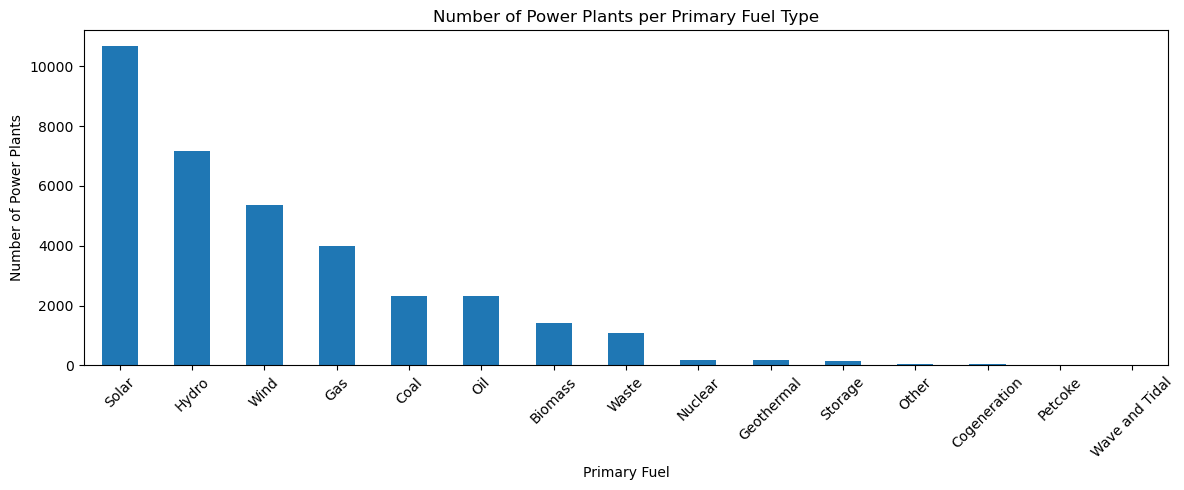

In [19]:
fuel_counts = get_frequency(df, "primary_fuel").dropna()

fuel_counts.plot(kind="bar", figsize=(12, 5))

plt.title("Number of Power Plants per Primary Fuel Type")
plt.xlabel("Primary Fuel")
plt.ylabel("Number of Power Plants")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

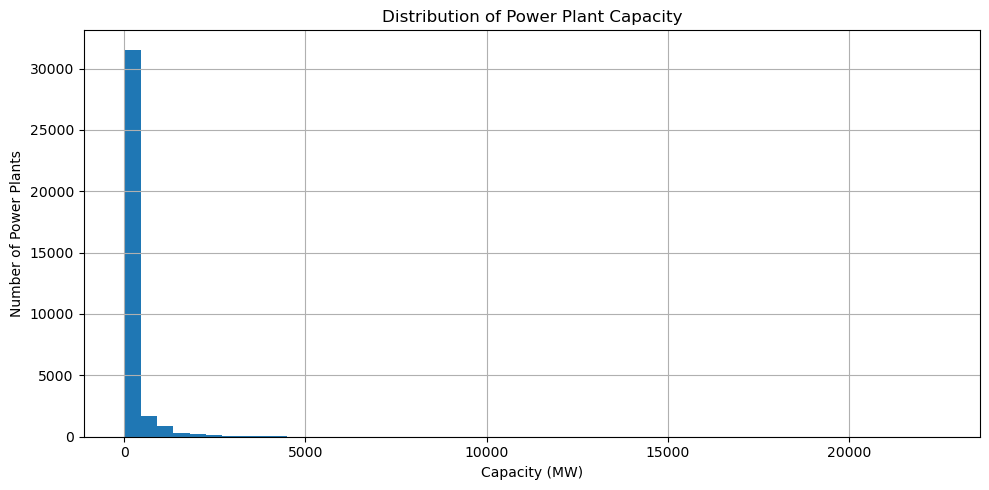

In [20]:
df["capacity_mw"].dropna().hist(bins=50, figsize=(10, 5))

plt.title("Distribution of Power Plant Capacity")
plt.xlabel("Capacity (MW)")
plt.ylabel("Number of Power Plants")
plt.tight_layout()
plt.show()

In [22]:
print("Number of power plants:", len(df))
print("Number of attributes:", len(df.columns))
print("Number of countries:", df["country"].nunique())
print("Number of fuel types:", df["primary_fuel"].nunique())

Number of power plants: 34936
Number of attributes: 36
Number of countries: 167
Number of fuel types: 15


The Global Power Plant Database contains information about
power plants worldwide. Each row represents an individual
power plant, while the columns describe characteristics such
as location, installed capacity, fuel type, ownership and
electricity generation.

The dataset combines numerical, categorical, geographical
and temporal attributes.

In [23]:
def missing_values_per_column(data):
    missing = data.isna().sum()
    percentage = (missing / len(data)) * 100

    result = pd.DataFrame({
        "Missing values": missing,
        "Percentage": percentage
    })

    return result.sort_values(
        by="Missing values",
        ascending=False
    )

display(missing_values_per_column(df))

,Missing values,Percentage
other_fuel3,34844,99.736661
other_fuel2,34660,99.209984
other_fuel1,32992,94.435539
generation_gwh_2013,28519,81.632127
generation_gwh_2014,27710,79.316464
generation_gwh_2015,26733,76.519922
generation_gwh_2016,25792,73.826425
generation_gwh_2017,25436,72.807419
generation_gwh_2018,25299,72.415274
generation_gwh_2019,25277,72.352301


In [24]:
def missing_values_per_row(data):
    return data.isna().sum(axis=1)

row_missing = missing_values_per_row(df)

print(row_missing.describe())

count    34936.000000
mean        13.048346
std          4.430825
min          2.000000
25%         11.000000
50%         14.000000
75%         16.000000
max         21.000000
dtype: float64


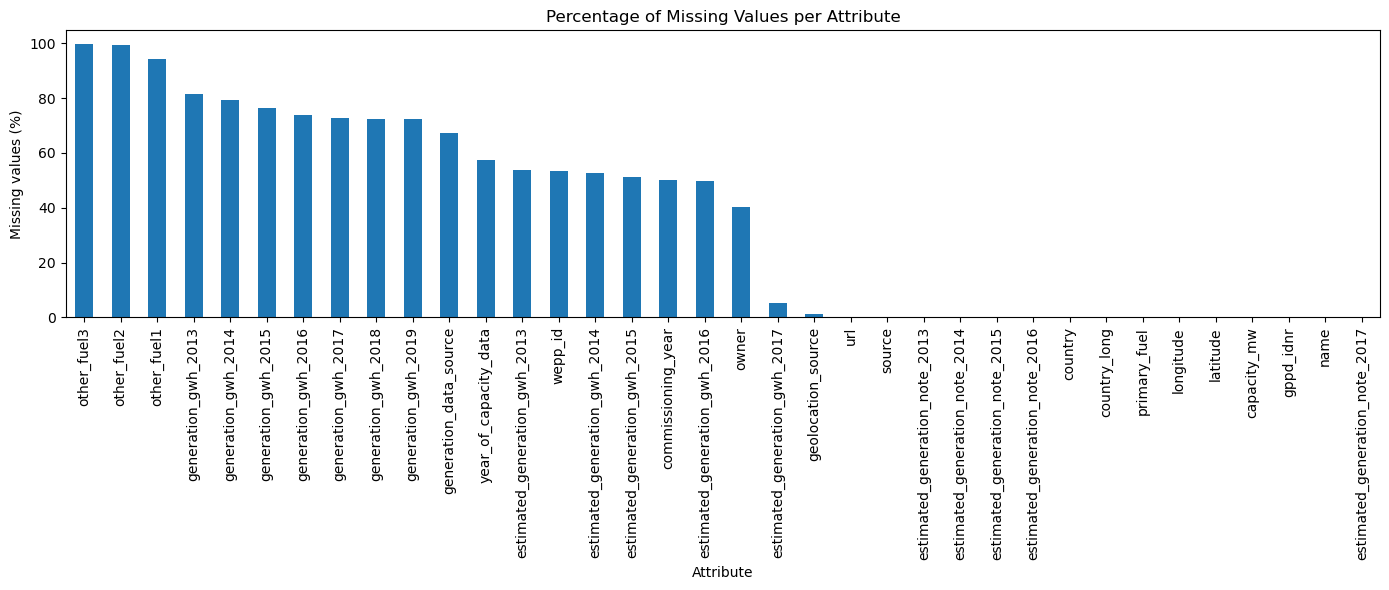

In [25]:
missing = missing_values_per_column(df)

missing["Percentage"].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Percentage of Missing Values per Attribute")
plt.xlabel("Attribute")
plt.ylabel("Missing values (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [26]:
missing = missing_values_per_column(df)

display(missing[missing["Percentage"] > 40])

,Missing values,Percentage
other_fuel3,34844,99.736661
other_fuel2,34660,99.209984
other_fuel1,32992,94.435539
generation_gwh_2013,28519,81.632127
generation_gwh_2014,27710,79.316464
generation_gwh_2015,26733,76.519922
generation_gwh_2016,25792,73.826425
generation_gwh_2017,25436,72.807419
generation_gwh_2018,25299,72.415274
generation_gwh_2019,25277,72.352301


In [27]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate plant IDs:", df["gppd_idnr"].duplicated().sum())

Duplicate rows: 0
Duplicate plant IDs: 0


In [28]:
invalid_latitude = (
    (df["latitude"] < -90) |
    (df["latitude"] > 90)
)

invalid_longitude = (
    (df["longitude"] < -180) |
    (df["longitude"] > 180)
)

print("Invalid latitudes:", invalid_latitude.sum())
print("Invalid longitudes:", invalid_longitude.sum())

Invalid latitudes: 0
Invalid longitudes: 0


In [29]:
print("Capacity values below or equal to zero:",
      (df["capacity_mw"] <= 0).sum())

display(df["capacity_mw"].describe())

Capacity values below or equal to zero: 0


count    34936.000000
mean       163.355148
std        489.636072
min          1.000000
25%          4.900000
50%         16.745000
75%         75.344250
max      22500.000000
Name: capacity_mw, dtype: float64

## Conclusion

The exploration provided an overview of the Global Power Plant
Database and its main characteristics.

The dataset contains numerical, categorical, geographical
and temporal attributes, which provide several possibilities
for visualization.

The analysis also identified missing values in several
attributes. These missing values need to be considered when
designing the visualization and deciding how to process the data.

The results of this exploration will be used to guide the
data handling and visualization design in the following stages
of the project.

## What is the purpose of this notebook?
Currently, it does the following:

1. Loaded the dataset
   
   Successfully loaded the CSV with pandas.
2. Inspected the structure
   34,936 × 36
   Power plants × attributes.
3. Identified the attributes
   
   Listed all 36 columns and their pandas data types.
4. Implemented a parsing function
   
   read_value() successfully retrieves a value using a row and column.
5. Implemented distribution functions
   
   get_frequency() and get_numeric_distribution() work.
6. Created distribution charts
   
   Fuel type bar chart and capacity histogram.
7. Analysed missing values
   
   Counts and percentages per attribute and per row.
8. Checked data quality
   
   Duplicate records, duplicate IDs, geographic coordinates and capacity values.

## What should we do next?
Exercise 2 – Goal
Next

Decide who will use the visualization and what questions they want to answer.

Exercise 3 – Data handling
After Exercise 2

Consider different ways to handle missing values and measurement errors, then implement one.

Exercise 4 – Data abstraction
After Exercise 3

Classify the attributes you intend to use according to Munzner's data abstraction framework.